# ECS529U Algorithms and Data Structures
# Lab sheet 8

This lab gets you to work with AVL trees and heaps.

At the end of this notebook there is an automated test script (it also includes tests for Question 2 if you need them, although that question is formative). You should run this on your solutions to check them. When you ask to have your work marked, you will get marked for those questions that pass the tests.

**Marks (max 10):**  Questions 1,3-6: 2 each | Question 2: formative

## Question 1 [2 marks]

This question is about understanding AVL trees. Consider the array `A`:

    A = ['ant', 'and', 'dog', 'hat', 'far', 'ear', 'anchor', 'fan', 'an', 'gas']

a) Draw the tree we obtain if we start from the empty AVL tree and add consecutively the numbers of the array `A`, starting from `A[0]`.
    
- Explain step-by-step how the first rotation in your tree was performed.
- Calculate the balance factors of all nodes in your final tree.

b) Draw the AVL tree we obtain if, starting from the tree built in part a, we remove its root.

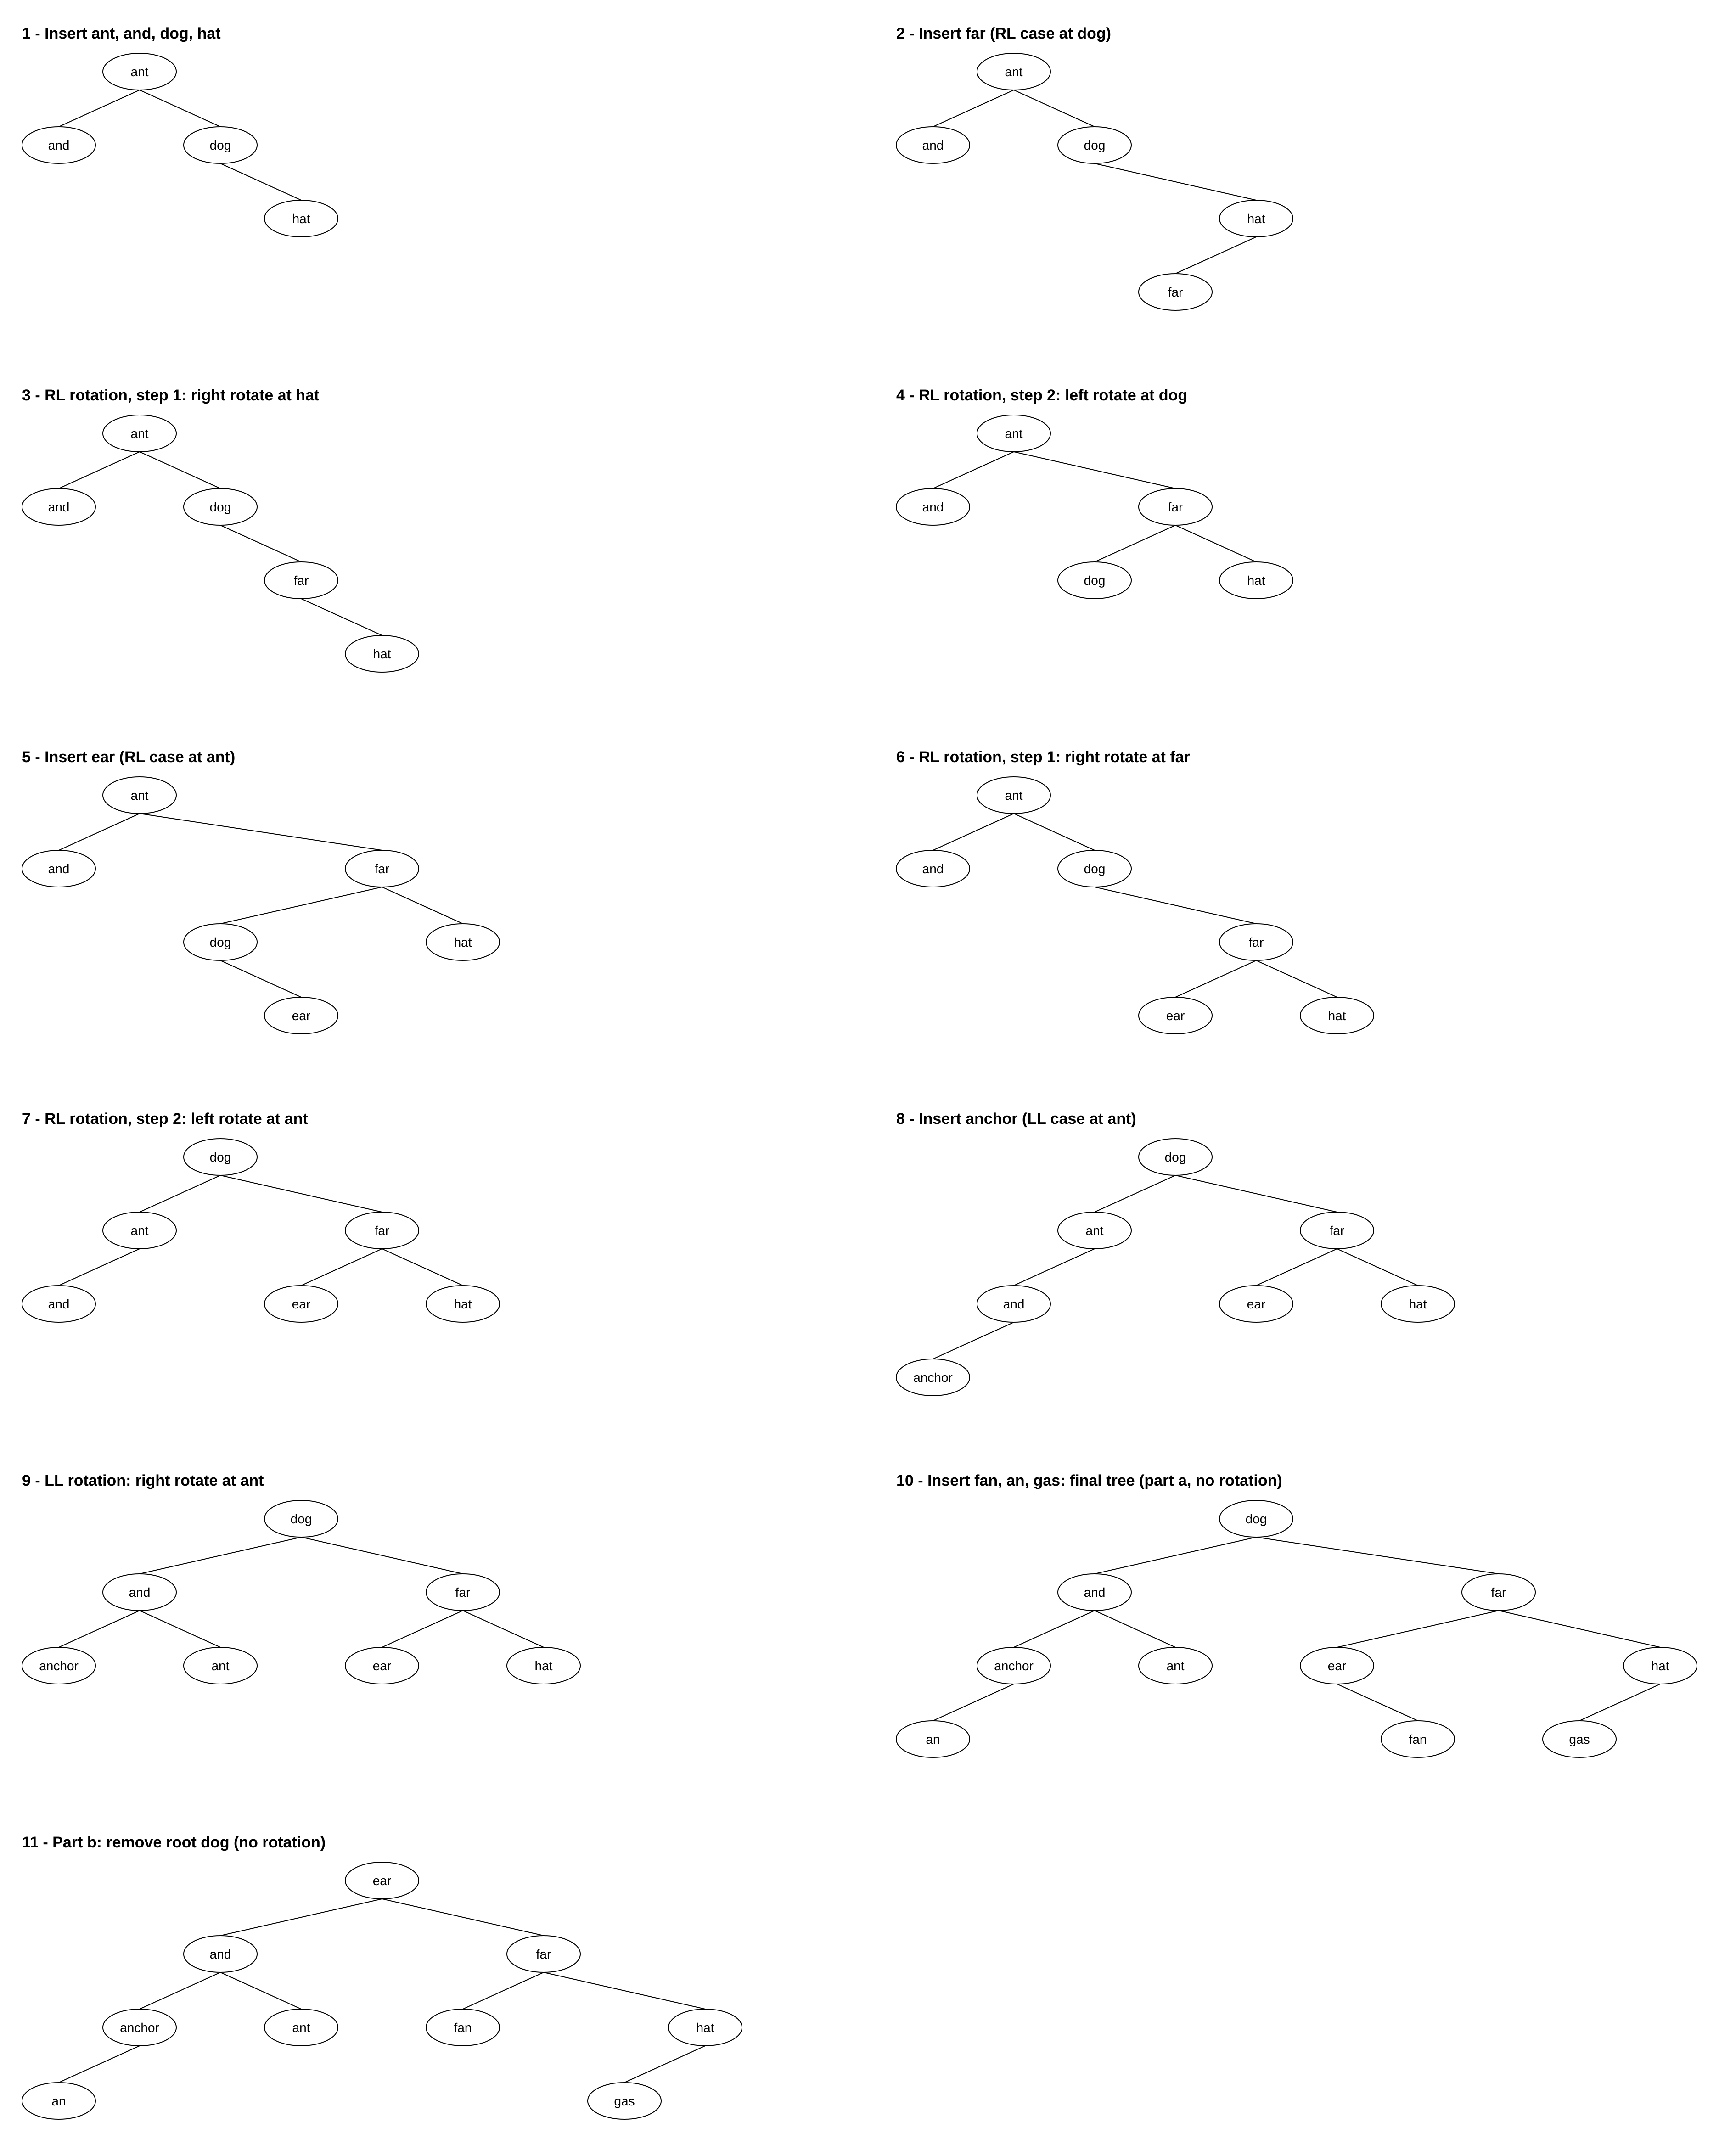

## Question 2 [formative]

Implement the function `remove` for the `AVLTree` class.

The function should remove elements exactly as the `remove` function of the `BST` class, but rebalance the tree after each node removal. You will need to extend the `_removeNode` function so as to take `path` as an additional argument and extend it (in case 3) with the nodes leading to the `minRNode`.

In [31]:
class AVLNode:
    def __init__(self,d,l,r):
        self.data = d
        self.left = l
        self.right = r
        self.updateHeight()

    def updateHeight(self):
        self.height = 1+max(AVLNode.getHeight(self.left),AVLNode.getHeight(self.right))        
        
    # ptr can be an AVLNode or None
    @staticmethod
    def getHeight(ptr):
        if ptr == None: return -1
        return ptr.height
        
    # prints the node and all its children in a string
    def __str__(self):  
        st = str(self.data)+" @"+str(self.height)+" -> ["
        if self.left != None:
            st += str(self.left)
        else: st += "None"
        if self.right != None:
            st += ", "+str(self.right)
        else: st += ", None"
        return st + "]"

    def niceStr(self): 
        S = ["├","─","└","│"]
        angle = S[2]+S[1]+" "
        vdash = S[0]+S[1]+" "
        
        def niceRec(ptr,acc,pre):
            if ptr == None: return acc+pre+"None @-1"
            data = acc+pre+str(ptr.data)+" @"+str(ptr.height)
            if ptr.left==ptr.right==None: return data
            if pre == vdash: pre2 = S[3]+"  "
            elif pre == angle: pre2 = "   "
            else: pre2 = ""
            left = niceRec(ptr.right,acc+pre2,vdash)
            right = niceRec(ptr.left,acc+pre2,angle)
            return data+"\n"+left+"\n"+right
            
        return niceRec(self,"","")    

class Stack: # a very simple stack implementation (no size function)
    class Node:
        def __init__(self,d,n):
            self.data = d
            self.next = n
                
    def __init__(self):
        self.top = None
        
    def push(self,d):
        self.top = Stack.Node(d,self.top)
        
    def pop(self):
        if self.top == None: return
        val = self.top.data
        self.top = self.top.next
        return val
        
# Assumes tree has no duplicates!
class AVLTree:
    def __init__(self):
        self.root = None
        self.size = 0
        
    def __str__(self):
        return str(self.root)
    
    def niceStr(self):
        if self.root == None: return "None"
        return self.root.niceStr()

    @staticmethod
    def _searchNode(ptr, d):
        if ptr == None: return None
        if d == ptr.data: return ptr
        if d < ptr.data:
            return AVLTree._searchNode(ptr.left, d)
        return AVLTree._searchNode(ptr.right, d)

    def search(self, d):   
        return AVLTree._searchNode(self.root, d) != None
            
    def add(self, d):
        if self.root == None:
            self.root = AVLNode(d,None,None)
        else:
            path = Stack()
            ptr = self.root
            while True:
                path.push(ptr)
                if d == ptr.data: raise Exception("duplicate addition!")
                if d < ptr.data:
                    if ptr.left == None:
                        ptr.left = AVLNode(d,None,None)
                        break
                    ptr = ptr.left
                else:
                    if ptr.right == None:
                        ptr.right = AVLNode(d,None,None)
                        break
                    ptr = ptr.right
            AVLTree._balance(path)
        self.size += 1
    
    @staticmethod
    def _balance(path):
        ptr = path.pop()

        while ptr != None:
            hl = AVLNode.getHeight(ptr.left)
            hr = AVLNode.getHeight(ptr.right)
            hptr = ptr.height            
            if hr-hl > 1: # right imbalance: right child too tall
                if AVLNode.getHeight(ptr.right.left) > AVLNode.getHeight(ptr.right.right):
                    AVLTree._rotateRight(ptr.right)
                    print("rotate right, then ",end="")
                AVLTree._rotateLeft(ptr)
                print("rotate left")    
            elif hl-hr > 1: # left imbalance: left child too tall
                if AVLNode.getHeight(ptr.left.right) > AVLNode.getHeight(ptr.left.left):
                    AVLTree._rotateLeft(ptr.left)
                    print("rotate left, then ",end="")
                AVLTree._rotateRight(ptr)
                print("rotate right")    
            else: # node balanced
                ptr.updateHeight()
            if hptr == ptr.height: # no more balancing needed 
                return
            ptr = path.pop()
        
    @staticmethod
    def _rotateLeft(ptr):
        n1 = ptr
        n2 = ptr.right
        c1 = ptr.left
        c2 = ptr.right.left
        c3 = ptr.right.right
        n1,n2 = n2,n1
        n1.data,n2.data = n2.data,n1.data
        n1.left,n1.right = c1,c2
        n1.updateHeight()
        n2.left,n2.right = n1,c3
        n2.updateHeight()
    
#      n1
#     / \
#    c1 n2
#      / \
#     c2 c3
#
# <rotates to>
#
#       n2
#      / \
#     n1 c3
#    / \
#   c1 c2
        
    @staticmethod
    def _rotateRight(ptr):
        n2 = ptr
        n1 = ptr.left
        c1 = ptr.left.left
        c2 = ptr.left.right
        c3 = ptr.right
        n1,n2 = n2,n1
        n1.data,n2.data = n2.data,n1.data
        n2.left,n2.right = c2,c3
        n2.updateHeight()
        n1.left,n1.right = c1,n2
        n1.updateHeight()

    def remove(self,d):
        
        return
        
t = AVLTree()
A = [1,2,3,4,5,6,7]
for x in A:
    t.add(x)
    print(t.niceStr(),"\n")
    
t = AVLTree()
t.add("cat")
t.add("car")
t.add("cav")
print(t.niceStr(),"\n")
t.add("cast")
t.add("put")
print(t.niceStr(),"\n")
t.add("cart")
print(t.niceStr(),"\n")
t.add("cs")
print(t.niceStr(),"\n")
print(t.search("cat"),t.remove("cat"),t.search("cat"),t.size)
print(t.niceStr(),"\n")
print(t.search("cat"),t.remove("cat"),t.search("cat"),t.size)
print(t.niceStr(),"\n")
print(t.search("put"),t.remove("put"),t.search("put"),t.size)
print(t.niceStr(),"\n")
print(t.search("cs"),t.remove("cs"),t.search("cs"),t.size)
print(t.niceStr(),"\n")
print(t.search("car"),t.remove("car"),t.search("car"),t.size)
print(t.niceStr(),"\n")
for x in ["cast","cav","cart"]: t.remove(x)
print(t.niceStr(),t.size)




# some testing code
t = AVLTree()
t.add("cat")
t.add("car")
t.add("cav")
print(t.niceStr(),"\n")
t.add("cast")
t.add("put")
print(t.niceStr(),"\n")
t.add("cart")
print(t.niceStr(),"\n")
t.add("cs")
print(t.niceStr(),"\n")
print(t.search("cat"),t.remove("cat"),t.search("cat"),t.size)
print(t.niceStr(),"\n")
print(t.search("cat"),t.remove("cat"),t.search("cat"),t.size)
print(t.niceStr(),"\n")
print(t.search("put"),t.remove("put"),t.search("put"),t.size)
print(t.niceStr(),"\n")
print(t.search("cs"),t.remove("cs"),t.search("cs"),t.size)
print(t.niceStr(),"\n")
print(t.search("car"),t.remove("car"),t.search("car"),t.size)
print(t.niceStr(),"\n")
for x in ["cast","cav","cart"]: t.remove(x)
print(t.niceStr(),t.size)

class ArrayList:
    def __init__(self):
        self.inArray = [0 for i in range(10)]
        self.count = 0
        
    def get(self, i):
        return self.inArray[i]

    def set(self, i, e):
        self.inArray[i] = e

    def length(self):
        return self.count

    def append(self, e):
        self.inArray[self.count] = e
        self.count += 1
        if len(self.inArray) == self.count:
            self._resizeUp()     # resize array if reached capacity

    def insert(self, i, e):
        for j in range(self.count,i,-1):
            self.inArray[j] = self.inArray[j-1]
        self.inArray[i] = e
        self.count += 1
        if len(self.inArray) == self.count:
            self._resizeUp()     # resize array if reached capacity

    def remove(self, i):
        self.count -= 1
        val = self.inArray[i]
        for j in range(i,self.count):
            self.inArray[j] = self.inArray[j+1]
        return val
    
    def __str__(self):
        return str(self.inArray[:self.count])

    def _resizeUp(self):
        newArray = [0 for i in range(2*len(self.inArray))]
        for j in range(len(self.inArray)):
            newArray[j] = self.inArray[j]
        self.inArray = newArray

1 @0 

1 @1
├─ 2 @0
└─ None @-1 

rotate left
2 @1
├─ 3 @0
└─ 1 @0 

2 @2
├─ 3 @1
│  ├─ 4 @0
│  └─ None @-1
└─ 1 @0 

rotate left
2 @2
├─ 4 @1
│  ├─ 5 @0
│  └─ 3 @0
└─ 1 @0 

rotate left
4 @2
├─ 5 @1
│  ├─ 6 @0
│  └─ None @-1
└─ 2 @1
   ├─ 3 @0
   └─ 1 @0 

rotate left
4 @2
├─ 6 @1
│  ├─ 7 @0
│  └─ 5 @0
└─ 2 @1
   ├─ 3 @0
   └─ 1 @0 

cat @1
├─ cav @0
└─ car @0 

cat @2
├─ cav @1
│  ├─ put @0
│  └─ None @-1
└─ car @1
   ├─ cast @0
   └─ None @-1 

rotate right, then rotate left
cat @2
├─ cav @1
│  ├─ put @0
│  └─ None @-1
└─ cart @1
   ├─ cast @0
   └─ car @0 

rotate right, then rotate left
cat @2
├─ cs @1
│  ├─ put @0
│  └─ cav @0
└─ cart @1
   ├─ cast @0
   └─ car @0 

True None True 7
cat @2
├─ cs @1
│  ├─ put @0
│  └─ cav @0
└─ cart @1
   ├─ cast @0
   └─ car @0 

True None True 7
cat @2
├─ cs @1
│  ├─ put @0
│  └─ cav @0
└─ cart @1
   ├─ cast @0
   └─ car @0 

True None True 7
cat @2
├─ cs @1
│  ├─ put @0
│  └─ cav @0
└─ cart @1
   ├─ cast @0
   └─ car @0 

True None True 7
cat @

## Question 3 [2]

This question is about understanding heaps. Consider the array `A`:

    A = ['ant', 'and', 'dog', 'hat', 'fan', 'ear', 'hat', 'fan', 'an', 'gas']    
    
a) Draw the heap we obtain if we start from the empty heap and add consecutively the numbers of the array `A`, starting from `A[0]`.

b) Draw the heap we obtain if we remove its root, using the technique followed by the `removeRoot` function that we saw in the lectures.

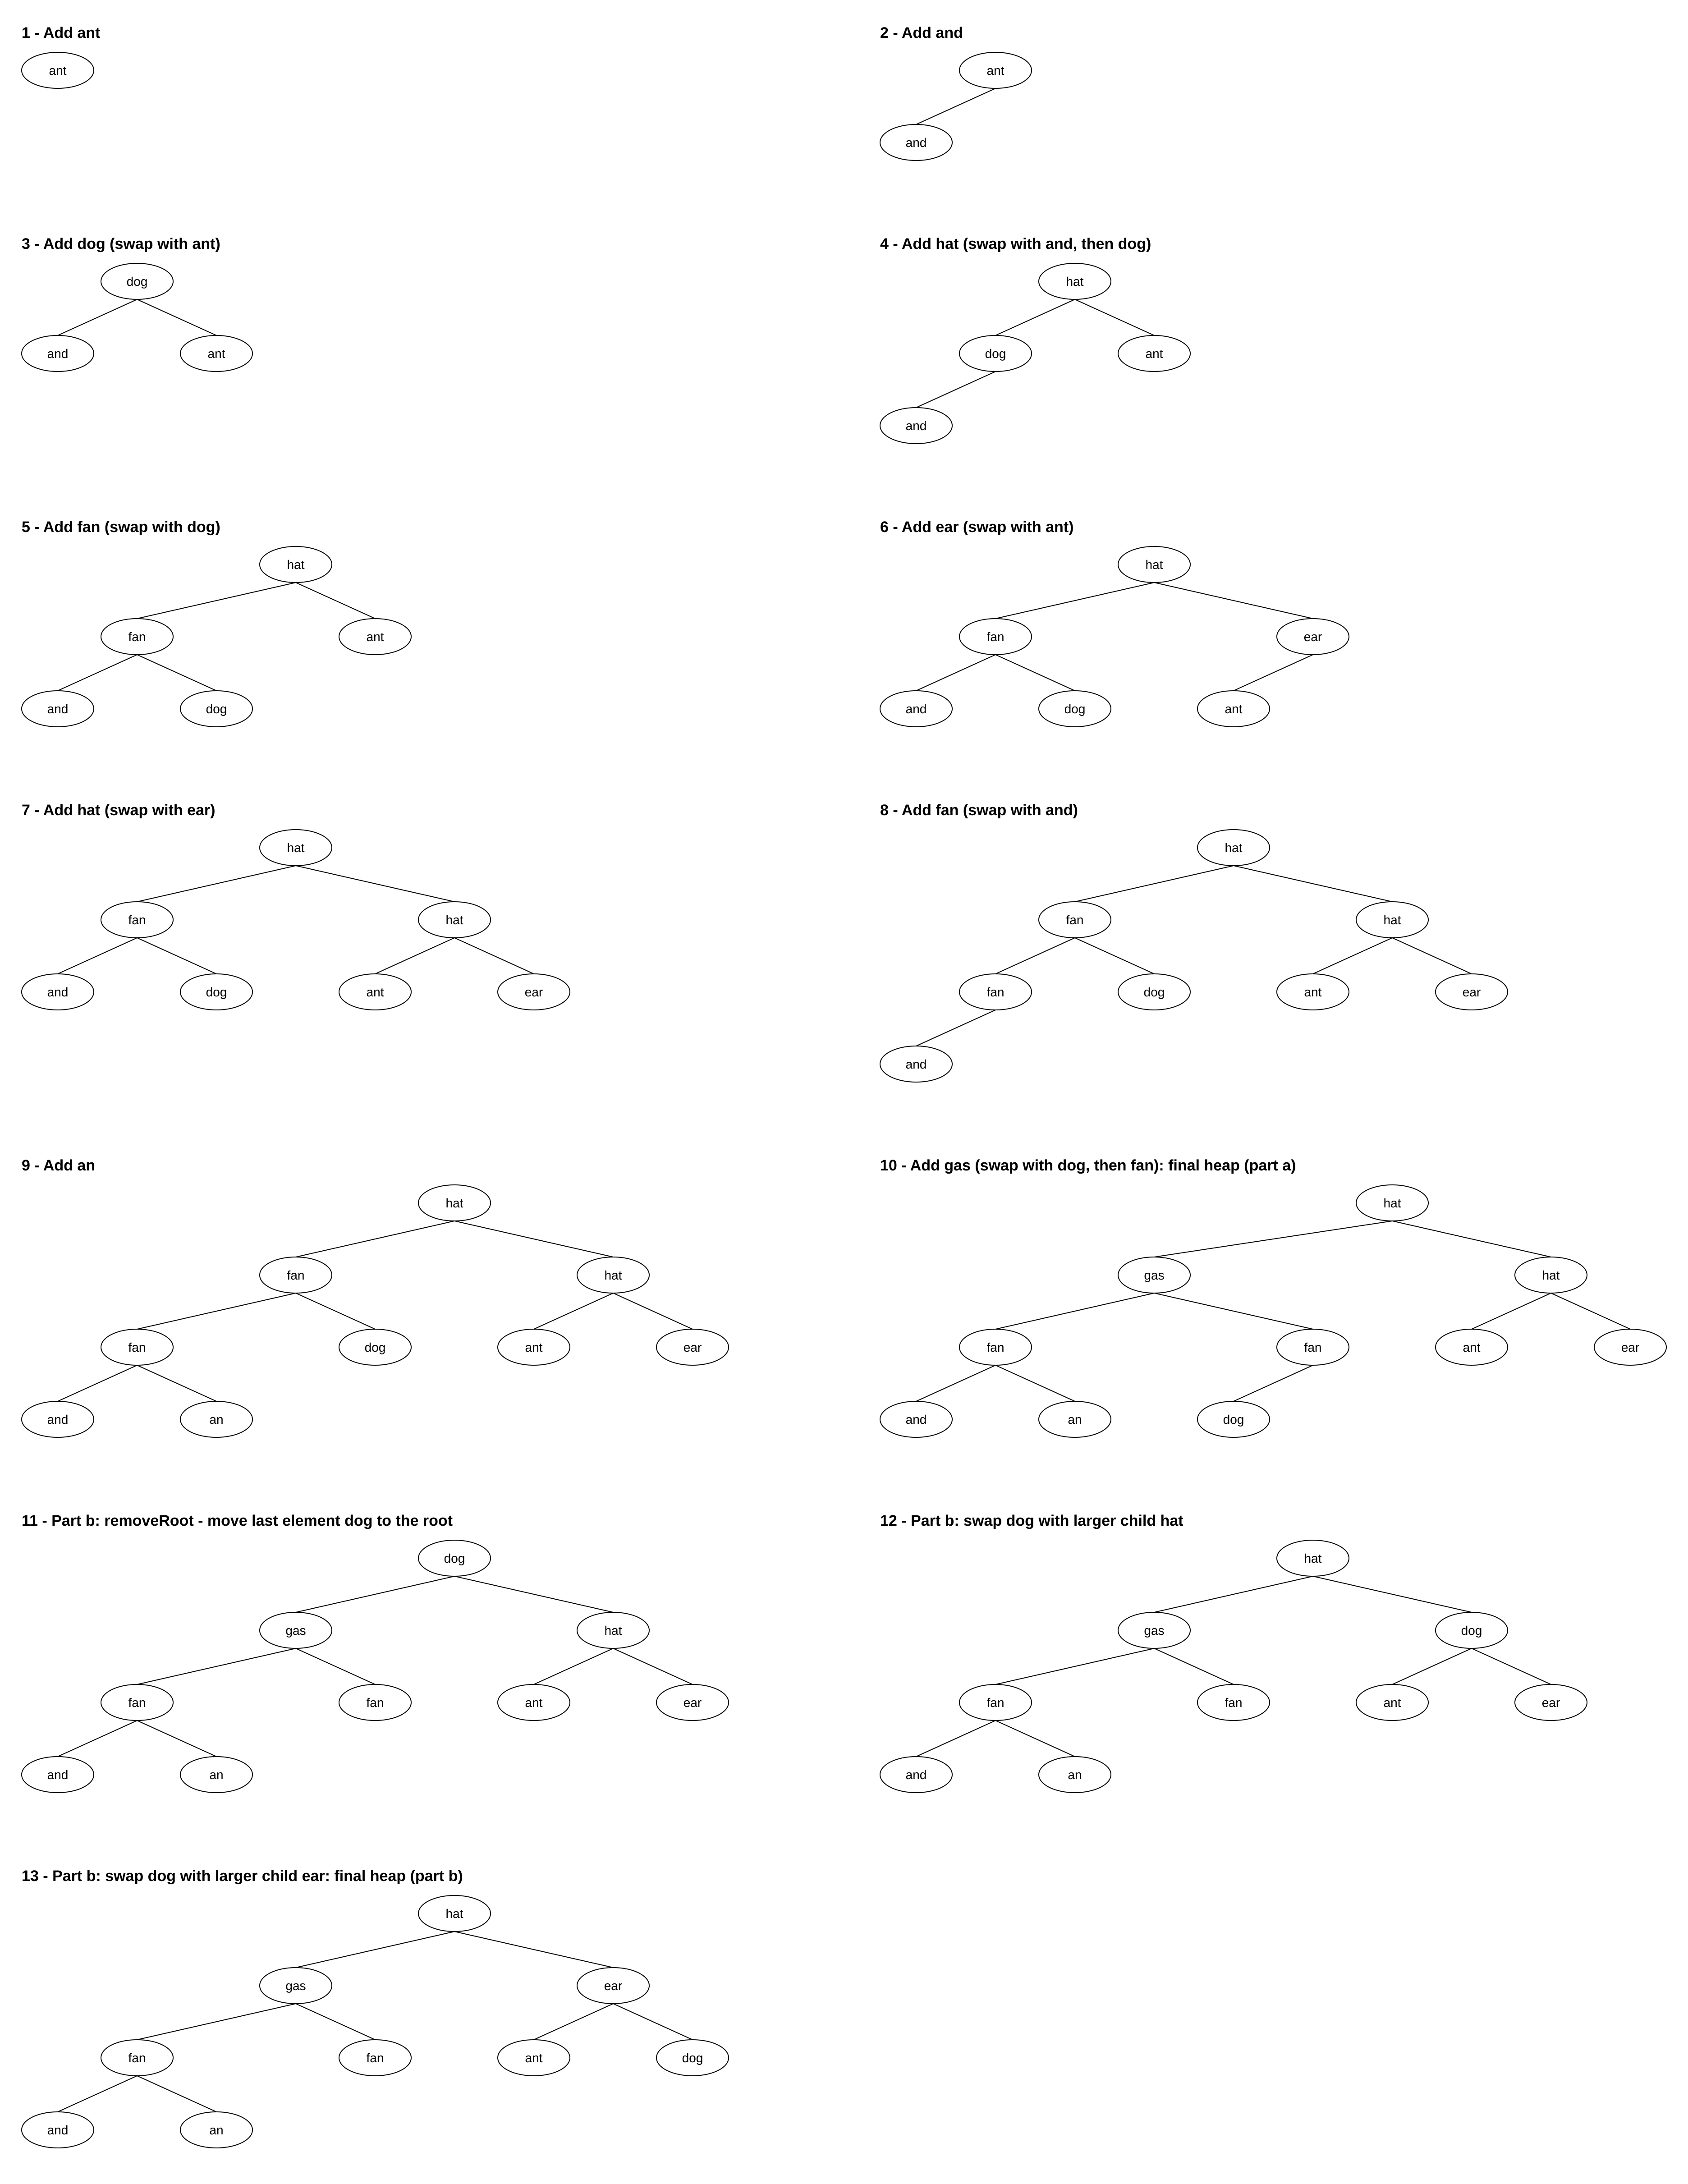

## Question 4 [2]

Add in `Heap` the following functions, assuming that we work with heaps that store comparable objects:

a) `def max(self)` [given]

that returns the largest element of the heap. If the heap is empty, the function should return `None`.

*Solution:* We note that the max element will be at the root:

    def max(self):
        if self.size == 0: return None
        return self.inList.get(0)

b) `def firstLeaf(self)`

that returns the position of the first leaf of the heap (in its array list representation). If the heap is empty, the function should return `None`. 

For example, if the heap `h` is represented by the list `[50, 50, 42, 12, 6, 9, 15, 1, 4, 6, 5, 8]` then `h.firstLeaf()` should return `6` (the element `15` is the first leaf). 

c) `def min(self)`

that returns the smallest element of the heap. If the heap is empty, the function should return `None`. This does not need to be an efficient implementation but your function should only search in the leaves of the heap (use `firstLeaf` from above).

*Hint:* You can do a linear search of the leaves of the heap in the underlying array list.

d) `def _search(self,d)`

that returns the position of the first occurrence of `d` in the heap (in its array list representation). If `d` is not in the heap, the function should return `-1`.

e) `toSortedArray(self)`

that returns a sorted array containing the elements of the heap. The heap should not be changed. 

For example, if the heap `h` is represented by the list `[50, 50, 42, 12, 6, 9, 5, 1, 4, 6, 5, 8]` then `h.toSortedArray` should return the array `[1, 4, 5, 5, 6, 6, 8, 9, 12, 42, 50, 50]`. 

In [32]:
class Heap:
    def __init__(self):
        self.inList = ArrayList()
        self.size = 0

    def __str__(self):
        return str(self.inList)

    def max(self):
        if self.size == 0: return None
        return self.inList.get(0)

    def firstLeaf(self):
        if self.size == 0: return None
        return self.size // 2

    def min(self):
        if self.size == 0: return None
        minVal = self.inList.get(self.firstLeaf())
        for i in range(self.firstLeaf() + 1, self.size):
            if self.inList.get(i) < minVal:
                minVal = self.inList.get(i)
        return minVal

    def _search(self, d):
        for i in range(self.size):
            if self.inList.get(i) == d:
                return i
        return -1

    def toSortedArray(self):
        # copy the heap so the original is not changed
        h = Heap()
        for i in range(self.size):
            h.append(self.inList.get(i))
        # removeRoot gives elements largest first, so fill A from the end
        A = [None] * self.size
        for i in range(self.size - 1, -1, -1):
            A[i] = h.removeRoot()
        return A

    def add(self, d):
        # add d in the bottom leaf position
        self.inList.append(d)
        # and then pull it up in its right position by swapping
        pos = self.size
        while pos > 0 and self.inList.get(pos) > self.inList.get((pos - 1) // 2):
            self._swap(pos, (pos - 1) // 2)
            pos = (pos - 1) // 2
        # increase the size of the heap
        self.size += 1

    def removeRoot(self):
        if self.size == 0: return None
        val = self.inList.get(0)
        self.inList.set(0, self.inList.get(self.size - 1))
        self.inList.remove(self.size - 1)
        self.size -= 1
        self.heapify(0)
        return val

    def heapify(self, pos):
        if self.size <= 2 * pos + 1: return
        if self.size <= 2 * pos + 2 or self.inList.get(2 * pos + 1) >= self.inList.get(2 * pos + 2):
            maxChild = 2 * pos + 1
        else:
            maxChild = 2 * pos + 2
        if self.inList.get(pos) < self.inList.get(maxChild):
            self._swap(pos, maxChild)
            self.heapify(maxChild)

    def _swap(self, i, j):
        temp = self.inList.get(i)
        self.inList.set(i, self.inList.get(j))
        self.inList.set(j, temp)

    def append(self, d):
        self.inList.append(d)
        self.size += 1

    def addAll(self, A):
        for x in A: self.add(x)

## Question 5 [2]

Add in `Heap` a function 

    def _remove(self,i)

that removes from the heap the element in position `i`. 

Then, using `_remove` and the function `_search` from Question 2, define a function 

    def removeVal(self, d)
    
that removes the first occurrence of `d` from the heap, and leaves the heap unchanged if `d` is not in it.

**Hint:** The difficult part with `_remove` is to make sure that, after removal, your tree remains a heap. Using the technique of `removeRoot` alone will not be enough!

In [33]:

class Heap:
    def __init__(self):
        self.inList = ArrayList()
        self.size = 0

    def __str__(self):
        return str(self.inList)

    def _remove(self, i):
        if i < 0 or i >= self.size: return None
        val = self.inList.get(i)
        # move the bottom leaf into position i
        self.inList.set(i, self.inList.get(self.size - 1))
        self.inList.remove(self.size - 1)
        self.size -= 1
        if i < self.size:
            # moved element may be larger than its parent: bubble up
            pos = i
            while pos > 0 and self.inList.get(pos) > self.inList.get((pos - 1) // 2):
                self._swap(pos, (pos - 1) // 2)
                pos = (pos - 1) // 2
            # or smaller than its children: bubble down
            self.heapify(pos)
        return val

    def removeVal(self, d):
        i = self._search(d)
        if i == -1: return None
        return self._remove(i)

    def max(self):
        if self.size == 0: return None
        return self.inList.get(0)

    def firstLeaf(self):
        if self.size == 0: return None
        return self.size // 2

    def min(self):
        if self.size == 0: return None
        minVal = self.inList.get(self.firstLeaf())
        for i in range(self.firstLeaf() + 1, self.size):
            if self.inList.get(i) < minVal:
                minVal = self.inList.get(i)
        return minVal

    def _search(self, d):
        for i in range(self.size):
            if self.inList.get(i) == d:
                return i
        return -1

    def toSortedArray(self):
        # copy the heap so the original is not changed
        h = Heap()
        for i in range(self.size):
            h.append(self.inList.get(i))
        # removeRoot gives elements largest first, so fill A from the end
        A = [None] * self.size
        for i in range(self.size - 1, -1, -1):
            A[i] = h.removeRoot()
        return A

    def add(self, d):
        # add d in the bottom leaf position
        self.inList.append(d)
        # and then pull it up in its right position by swapping
        pos = self.size
        while pos > 0 and self.inList.get(pos) > self.inList.get((pos - 1) // 2):
            self._swap(pos, (pos - 1) // 2)
            pos = (pos - 1) // 2
        # increase the size of the heap
        self.size += 1

    def removeRoot(self):
        if self.size == 0: return None
        val = self.inList.get(0)
        self.inList.set(0, self.inList.get(self.size - 1))
        self.inList.remove(self.size - 1)
        self.size -= 1
        self.heapify(0)
        return val

    def heapify(self, pos):
        if self.size <= 2 * pos + 1: return
        if self.size <= 2 * pos + 2 or self.inList.get(2 * pos + 1) >= self.inList.get(2 * pos + 2):
            maxChild = 2 * pos + 1
        else:
            maxChild = 2 * pos + 2
        if self.inList.get(pos) < self.inList.get(maxChild):
            self._swap(pos, maxChild)
            self.heapify(maxChild)

    def _swap(self, i, j):
        temp = self.inList.get(i)
        self.inList.set(i, self.inList.get(j))
        self.inList.set(j, temp)

    def append(self, d):
        self.inList.append(d)
        self.size += 1

    def addAll(self, A):
        for x in A: self.add(x)

#some testing code
h = Heap()
for x in [50, 50, 42, 12, 6, 9, 5, 1, 4, 6, 5, 8]: h.add(x)
print(h,h.min())
h.removeVal(9)
print(h)
h.add(42)
print(h)
print(h.toSortedArray())
print(h)

[50, 50, 42, 12, 6, 9, 5, 1, 4, 6, 5, 8] 1
[50, 50, 42, 12, 6, 8, 5, 1, 4, 6, 5]
[50, 50, 42, 12, 6, 42, 5, 1, 4, 6, 5, 8]
[1, 4, 5, 5, 6, 6, 8, 12, 42, 42, 50, 50]
[50, 50, 42, 12, 6, 42, 5, 1, 4, 6, 5, 8]


## Priority Queues

For the next question, we look again at priority queues. A priority queue is a queue in 
which each element has a priority, and where dequeueing always returns the item with the 
greatest priority in the queue.

We start by defining a class of priority queue elements (PQ-elements for short):

    class PQElement:
        def __init__(self, v, p):
            self.val = v
            self.priority = p

So, a PQ-element is a pair consisting of a value (which can be anything, e.g. an integer, a 
string, an array, etc.) and a priority (which is an integer). 

In Lab 5 we also implemented the `__str__` function to be able to print PQ-elements.

## Question 6 [2]

Write a Python class `PQueue` that implements a priority queue using a heap of 
`PQElement`’s. In particular, you need to implement 5 functions:
- one for creating an empty priority queue [given]
- one for returning the size of the priority queue [given]
- one for enqueueing a new PQ-element in the priority queue
- one for dequeueing from the priority queue the PQ-element with the greatest priority
- one that prints the elements of the priority queue into a string (call this one `__str__`)

Test each of the functions on examples of your own making. For example, running:

    pq = PQueue()
    A = [(1,9),(3,7),(13,-3),(0,10),(4,6),(5,5),(6,4),(2,8),(7,3),(9,1),(14,-4),(10,0),(11,-1),(8,2),(12,-2)]
    for x in A: pq.enq(PQElement(x[0],x[1]))
    print(pq)
    print(pq.deq(),pq)

should give this printout:

    [(0,10),(1,9),(2,8),(3,7),(4,6),(5,5),(6,4),(7,3),(8,2),(9,1),(10,0),(11,-1),(12,-2),(13,-3),(14,-4)]
    (0,10) [(1,9),(2,8),(3,7),(4,6),(5,5),(6,4),(7,3),(8,2),(9,1),(10,0),(11,-1),(12,-2),(13,-3),(14,-4)]

**Note:** the `str` function should print the queue elements in descending priority order, without changing 
the queue. One idea is to use the function `toSortedArray` from Question 4.

In [34]:
# important: str should print elements in order of priority, without destroying or changing the queue

class PQueue:
    def __init__(self):
        self.inHeap = Heap()

    def size(self):
        return self.inHeap.size

    def deq(self):
        return self.inHeap.removeRoot()

    def enq(self, e):
        self.inHeap.add(e)

    def __str__(self):
        # toSortedArray is ascending and doesn't change the heap, so reverse it
        A = self.inHeap.toSortedArray()
        return "[" + ",".join(str(A[i]) for i in range(len(A) - 1, -1, -1)) + "]"
# some testing code
pq = PQueue()
A = [(1,9),(3,7),(13,-3),(0,10),(4,6),(5,5),(6,4),(2,8),(7,3),(9,1),(14,-4),(10,0),(11,-1),(8,2),(12,-2)]
for x in A: pq.enq(PQElement(x[0],x[1]))
print(pq)
print(pq.deq(),pq)

[(0,10),(1,9),(2,8),(3,7),(4,6),(5,5),(6,4),(7,3),(8,2),(9,1),(10,0),(11,-1),(12,-2),(13,-3),(14,-4)]
(0,10) [(1,9),(2,8),(3,7),(4,6),(5,5),(6,4),(7,3),(8,2),(9,1),(10,0),(11,-1),(12,-2),(13,-3),(14,-4)]


In [35]:
class ArrayList:
    def __init__(self):
        self.inArray = [0 for i in range(10)]
        self.count = 0
        
    def swap(self, i, j):
        tmp = self.inArray[i]
        self.inArray[i] = self.inArray[j]
        self.inArray[j] = tmp
    
    def get(self, i):
        return self.inArray[i]

    def set(self, i, e):
        self.inArray[i] = e

    def length(self):
        return self.count

    def append(self, e):
        self.inArray[self.count] = e
        self.count += 1
        if len(self.inArray) == self.count:
            self._resizeUp()     # resize array if reached capacity

    def insert(self, i, e):
        for j in range(self.count,i,-1):
            self.inArray[j] = self.inArray[j-1]
        self.inArray[i] = e
        self.count += 1
        if len(self.inArray) == self.count:
            self._resizeUp()     # resize array if reached capacity

    def remove(self, i):
        self.count -= 1
        val = self.inArray[i]
        for j in range(i,self.count):
            self.inArray[j] = self.inArray[j+1]
        return val

    # Clones the array list and returns the clone. The two copies are independent
    def clone(self):
        a = ArrayList()
        a.inArray = self.inArray[:]
        a.count = self.count
        return a
    
    def __str__(self):
        return str(self.inArray[:self.count])

    def _resizeUp(self):
        newArray = [0 for i in range(2*len(self.inArray))]
        for j in range(len(self.inArray)):
            newArray[j] = self.inArray[j]
        self.inArray = newArray

In [36]:
# ===== Test cell. Code was produced with Claude =====
# ===== This cell should be AFTER your solutions (Questions 2, 4, 5 and 6) and the ArrayList class =====

import random, sys, io, contextlib
from itertools import permutations

# ---------- helpers ----------

def _short(x, n=60):
    s = str(x)
    return s if len(s) <= n else s[:n - 3] + "..."

def _profile(f, *args):
    # run f(*args); return (result, names of the functions called)
    names = set()
    def prof(frame, event, arg):
        if event == "call":
            names.add(frame.f_code.co_name)
    old = sys.getprofile()
    sys.setprofile(prof)
    try:
        result = f(*args)
    finally:
        sys.setprofile(old)
    return result, names

_rng = random.Random()

# ----- AVL trees -----

def _avl(A):
    # build an AVL tree by adding the elements of A in order (using add from the lecture)
    t = AVLTree()
    for x in A:
        t.add(x)
    return t

def _avl_nodes(t, limit=10000):
    # all nodes of the tree (in-order), or None if the structure is not a tree
    out, stack, seen, ptr = [], [], set(), t.root
    while stack or ptr is not None:
        while ptr is not None:
            if id(ptr) in seen or len(seen) > limit:
                return None
            seen.add(id(ptr))
            stack.append(ptr)
            ptr = ptr.left
        ptr = stack.pop()
        out.append(ptr)
        ptr = ptr.right
    return out

def _avl_shape(t):
    # the values of the tree in pre-order, with None for the empty subtrees
    out, stack = [], [t.root]
    while stack and len(out) < 100000:
        ptr = stack.pop()
        if ptr is None:
            out.append(None)
        else:
            out.append(ptr.data)
            stack.append(ptr.right)
            stack.append(ptr.left)
    return out

def _avl_check(t, expected):
    # t must be a valid AVL tree holding exactly the values in `expected`:
    # BST order, every node balanced, correct stored heights, correct size
    N = _avl_nodes(t)
    if N is None:
        return "the tree structure is broken (a node is reachable twice)"
    vals = [n.data for n in N]
    if sorted(vals) != sorted(expected):
        return f"the tree holds {_short(sorted(vals))}, expected {_short(sorted(expected))}"
    if any(vals[i] > vals[i + 1] for i in range(len(vals) - 1)):
        return "the tree is not a BST any more"
    height, stack = {None: -1}, [(t.root, False)]   # real heights, computed bottom-up
    while stack:
        ptr, done = stack.pop()
        if ptr is None:
            continue
        if not done:
            stack += [(ptr, True), (ptr.left, False), (ptr.right, False)]
            continue
        hl = height[None if ptr.left is None else id(ptr.left)]
        hr = height[None if ptr.right is None else id(ptr.right)]
        height[id(ptr)] = 1 + max(hl, hr)
        if abs(hl - hr) > 1:
            return (f"the tree is not balanced: the node holding {ptr.data!r} has a left subtree "
                    f"of height {hl} and a right subtree of height {hr}")
        if ptr.height != height[id(ptr)]:
            return (f"the node holding {ptr.data!r} stores height {ptr.height}, "
                    f"but its real height is {height[id(ptr)]}")
    if t.size != len(expected):
        return f"size is {t.size}, expected {len(expected)}"
    return True

# ----- heaps -----

def _heap(L):
    # the heap whose array list representation is exactly L (L must be a valid heap)
    h = Heap()
    for x in L:
        h.inList.append(x)
        h.size += 1
    return h

def _content(h):
    return [h.inList.get(i) for i in range(h.size)]

def _heapList(A):
    # the array list representation of the heap we get by adding the elements of A in order
    H = []
    for x in A:
        H.append(x)
        i = len(H) - 1
        while i > 0 and H[i] > H[(i - 1) // 2]:
            H[i], H[(i - 1) // 2] = H[(i - 1) // 2], H[i]
            i = (i - 1) // 2
    return H

def _check_heap(h, expected):
    # h must be a valid heap holding exactly the values in `expected`
    if not isinstance(h.size, int) or h.size < 0:
        return f"size is {h.size!r}"
    if h.inList.length() != h.size:
        return f"the heap has size {h.size} but its array list has {h.inList.length()} elements"
    C = _content(h)
    if sorted(C) != sorted(expected):
        return f"the heap holds {_short(sorted(C))}, expected {_short(sorted(expected))}"
    for i in range(1, len(C)):
        if C[i] > C[(i - 1) // 2]:
            return (f"not a heap any more: {C[i]!r} in position {i} is larger than "
                    f"its parent {C[(i - 1) // 2]!r} in position {(i - 1) // 2}")
    return True

def _unchanged(h, L):
    # the heap must be exactly as it was (same array list representation)
    if h.size != len(L) or h.inList.length() != len(L):
        return f"the heap was changed: its size is now {h.size}, it was {len(L)}"
    C = _content(h)
    if len(C) != len(L) or any(C[i] is not L[i] and C[i] != L[i] for i in range(len(L))):
        return f"the heap was changed: it is now {_short(C)}, it was {_short(L)}"
    return True

class _Item:
    # a value that remembers which items took part in a comparison;
    # two items with the same value are equal, but they are different objects
    seen = None
    def __init__(self, v, tag=""):
        self.v, self.tag = v, tag
    def _other(self, other):
        if _Item.seen is not None:
            _Item.seen.add(id(self))
            _Item.seen.add(id(other))
        return other.v if isinstance(other, _Item) else other
    def __lt__(self, other): return self.v < self._other(other)
    def __le__(self, other): return self.v <= self._other(other)
    def __gt__(self, other): return self.v > self._other(other)
    def __ge__(self, other): return self.v >= self._other(other)
    def __eq__(self, other): return self.v == self._other(other)
    def __ne__(self, other): return self.v != self._other(other)
    def __repr__(self): return str(self.v) + self.tag

_EX = [50, 50, 42, 12, 6, 9, 5, 1, 4, 6, 5, 8]
_EX2 = [50, 50, 42, 12, 6, 9, 15, 1, 4, 6, 5, 8]
_HEAPS = [                                   # (description, array list representation)
    ("the empty heap", []),
    ("[5]", [5]),
    ("[9, 4]", [9, 4]),
    ("[3, 1, 2]", [3, 1, 2]),
    (f"{_EX} (example)", _EX),
    (f"{_EX2} (example)", _EX2),
    ("[10, 9, 1, 8, 7] (the 1 is not on the bottom level)", [10, 9, 1, 8, 7]),
    ("[50, 45, 42, 42]", [50, 45, 42, 42]),
    ("[7, 7, 7, 7, 7]", [7, 7, 7, 7, 7]),
    ("[8, 3, -1, 0, -5, -10]", [8, 3, -1, 0, -5, -10]),
    ("a heap of strings", ['hat', 'gas', 'hat', 'fan', 'fan', 'ant', 'ear', 'and', 'an', 'dog']),
    ("a heap with 15 elements (full bottom level)", _heapList([_rng.randint(1, 99) for _ in range(15)])),
    ("a heap with 16 elements (one element on the bottom level)", _heapList([_rng.randint(1, 99) for _ in range(16)])),
    ("a heap with 100 random values with repeats", _heapList([_rng.randint(-50, 50) for _ in range(100)])),
    ("a heap built from 200 increasing values", _heapList(list(range(1, 201)))),
]

# Each test is a pair (description, function). The function returns True if the
# test passes, or a string explaining what went wrong.

# ---------- Question 2: remove for AVL trees ----------

def _q2_case(A, removes, label):
    def run():
        t = _avl(A)
        rest = list(A)
        for x in removes:
            shape = _avl_shape(t)
            t.remove(x)
            if x in rest:
                rest.remove(x)
            elif _avl_shape(t) != shape:
                return f"remove({x!r}) changed the tree, but {x!r} was not in it"
            r = _avl_check(t, rest)
            if r is not True:
                return f"after remove({x!r}): {r}"
        if removes:
            t.add(removes[0])               # the tree must still work afterwards
            r = _avl_check(t, rest + [removes[0]])
            if r is not True:
                return "after remove, add does not work: " + r
        return True
    return (label, run)

def _q2_small_trees():
    # every tree we can build from up to 5 values, removing each of its values
    for n in range(1, 6):
        for A in permutations(range(n)):
            for x in A:
                t = _avl(A)
                t.remove(x)
                r = _avl_check(t, [y for y in A if y != x])
                if r is not True:
                    return f"add {list(A)}, then remove({x}): {r}"
    return True

def _fib(h, lo=0):
    # values of a sparsest AVL tree of height h, level by level; its left subtrees are the tall ones
    def size(h): return 0 if h < 0 else 1 + size(h - 1) + size(h - 2)
    levels = {}
    def build(h, lo, depth):
        if h < 0: return
        root = lo + size(h - 1)
        levels.setdefault(depth, []).append(root)
        build(h - 1, lo, depth + 1)
        build(h - 2, root + 1, depth + 1)
    build(h, lo, 0)
    return [x for d in sorted(levels) for x in levels[d]]

_W = ["cat", "car", "cav", "cast", "put", "cart", "cs"]
_Q1 = ['ant', 'and', 'dog', 'hat', 'far', 'ear', 'anchor', 'fan', 'an', 'gas']
_R60 = _rng.sample(range(1000), 60)
_R300 = _rng.sample(range(10000), 300)
_F = _fib(6)
TESTS_Q2 = [
    _q2_case(_W, ["cat", "cat", "put", "cs", "car", "cast", "cav", "cart"], "the test code of Question 2"),
    _q2_case(_Q1, ["dog", "ant"], "the tree of Question 1: remove 'dog' (the root), then 'ant'"),
    _q2_case([], [5], "remove on the empty tree"),
    _q2_case([5], [5], "remove the only element"),
    _q2_case([5, 3, 8, 1, 4, 7, 9], [6], "remove a value that is not in the tree"),
    _q2_case([5, 3, 8, 1, 4, 7, 9], [1], "remove a leaf (no rotation needed)"),
    _q2_case([5, 3, 8, 1], [3], "remove a node with one child"),
    _q2_case([5, 3, 8, 1, 4, 7, 9], [5], "remove the root, which has two children"),
    _q2_case([5, 3, 8, 1, 4, 7, 9], [3, 8], "remove inner nodes with two children"),
    _q2_case([2, 1, 3, 4], [1], "add [2, 1, 3, 4], remove 1 (needs a left rotation)"),
    _q2_case([3, 4, 2, 1], [4], "add [3, 4, 2, 1], remove 4 (needs a right rotation)"),
    _q2_case([2, 1, 4, 3], [1], "add [2, 1, 4, 3], remove 1 (needs a right, then a left rotation)"),
    _q2_case([3, 4, 1, 2], [4], "add [3, 4, 1, 2], remove 4 (needs a left, then a right rotation)"),
    _q2_case([50, 30, 70, 20, 40, 60, 80, 10, 90], [50],
             "add [50, 30, 70, 20, 40, 60, 80, 10, 90], remove 50 (needs a rotation below the root)"),
    _q2_case([50, 30, 80, 20, 40, 70, 90, 10, 60], [50],
             "add [50, 30, 80, 20, 40, 70, 90, 10, 60], remove 50 (heights change below the root)"),
    _q2_case(_F, [max(_F)], "remove the largest value of a sparse AVL tree of height 6 (several rotations)"),
    _q2_case(_F, sorted(_F, reverse=True), "remove all values of a sparse AVL tree of height 6, largest first"),
    ("every tree with up to 5 values, removing each of its values", _q2_small_trees),
    _q2_case(list(range(1, 41)), list(range(1, 41)), "add 1..40, then remove them in increasing order"),
    _q2_case(list(range(1, 41)), list(range(40, 0, -1)), "add 1..40, then remove them in decreasing order"),
    _q2_case(_R60, _rng.sample(_R60, 60), "add 60 random values, then remove them all in random order"),
    _q2_case(_R300, _rng.sample(_R300, 100), "add 300 random values, then remove 100 of them"),
]

# ---------- Question 4: max, firstLeaf, min, _search, toSortedArray ----------

def _q4_max(label, L):
    def run():
        h = _heap(L)
        out = h.max()
        expected = max(L) if L else None
        if out != expected or (expected is None and out is not None):
            return f"returned {out!r}, expected {expected!r}"
        return _unchanged(h, L)
    return (f"max of {label}", run)

def _q4_firstLeaf(L, label):
    def run():
        h = _heap(L)
        out = h.firstLeaf()
        expected = len(L) // 2 if L else None
        if out != expected or (expected is None and out is not None) or isinstance(out, float):
            why = "" if expected is None else f" (the leaves are in positions {expected} to {len(L) - 1})"
            return f"returned {out!r}, expected {expected!r}{why}"
        return _unchanged(h, L)
    return (f"firstLeaf of {label}", run)

def _q4_min(label, L):
    def run():
        h = _heap(L)
        out = h.min()
        expected = min(L) if L else None
        if out != expected or (expected is None and out is not None):
            return f"returned {out!r}, expected {expected!r}"
        return _unchanged(h, L)
    return (f"min of {label}", run)

def _q4_min_leaves(L, label):
    def run():
        items = [_Item(x) for x in L]
        h = _heap(items)
        _Item.seen = set()
        try:
            out = h.min()
        finally:
            seen, _Item.seen = _Item.seen, None
        if not isinstance(out, _Item) or out.v != min(L):
            return f"returned {out!r}, expected {min(L)!r}"
        inner = [i for i in range(len(L) // 2) if id(items[i]) in seen]
        if inner:
            return (f"min compared the elements in positions {_short(inner, 30)}, which are not leaves "
                    f"(the leaves are in positions {len(L) // 2} to {len(L) - 1})")
        return True
    return (f"min only looks at the leaves of {label}", run)

def _q4_min_uses_firstLeaf():
    h = _heap(_EX)
    _, names = _profile(h.min)
    return True if "firstLeaf" in names else "min does not call firstLeaf"

def _q4_search(L, d, label=None):
    def run():
        h = _heap(L)
        out = h._search(d)
        expected = L.index(d) if d in L else -1
        if out != expected or isinstance(out, (float, bool)) or out is None:
            return f"returned {out!r}, expected {expected!r}"
        return _unchanged(h, L)
    return (label or f"_search({d!r}) on {_short(L, 50)}", run)

def _q4_search_all(label, L):
    # search for every value of the heap, and for some values that are not in it
    def run():
        h = _heap(L)
        if L and isinstance(L[0], str):
            absent = ["", "b", "zzz"]
        else:
            absent = [min(L, default=0) - 1, max(L, default=0) + 1, 0.5]
        for d in list(dict.fromkeys(L)) + absent:
            out = h._search(d)
            expected = L.index(d) if d in L else -1
            if out != expected or isinstance(out, (float, bool)) or out is None:
                return f"_search({d!r}) returned {out!r}, expected {expected!r}"
        return _unchanged(h, L)
    return (f"_search for every value of {label}", run)

def _q4_search_removed():
    h = _heap(_heapList([9, 4, 7, 1]))
    h.removeRoot()                          # removeRoot from the lecture
    out = h._search(9)
    return True if out == -1 else f"returned {out!r}, expected -1"

def _q4_sorted(label, L, removals=0):
    def run():
        h = _heap(L)
        for _ in range(removals):
            h.removeRoot()                  # removeRoot from the lecture
        L2 = _content(h)
        out = h.toSortedArray()
        if not isinstance(out, list):
            return f"returned a {type(out).__name__}, expected an array (Python list)"
        if out != sorted(L2):
            return f"returned {_short(out)}, expected {_short(sorted(L2))}"
        r = _unchanged(h, L2)
        if r is not True:
            return r
        if out:
            out[0] = out[-1]                # a second call must give a fresh, correct array
            if h.toSortedArray() != sorted(L2):
                return "changing the returned array changed the next result"
            r = _unchanged(h, L2)
            if r is not True:
                return "after a second call, " + r
        top = max(L2) if L2 else "m"
        h.add(top)                          # the heap must still work afterwards
        r = _check_heap(h, L2 + [top])
        return True if r is True else "after toSortedArray, add does not work: " + r
    return (f"toSortedArray of {label}", run)

TESTS_Q4 = [_q4_max(label, L) for label, L in _HEAPS]
TESTS_Q4 += [_q4_firstLeaf(L, label) for label, L in _HEAPS]
TESTS_Q4 += [_q4_firstLeaf(list(range(n, 0, -1)), f"a heap with {n} elements") for n in range(2, 41)]
TESTS_Q4 += [_q4_min(label, L) for label, L in _HEAPS]
TESTS_Q4 += [_q4_min(f"a heap built from {_short(A, 40)}", _heapList(A))
             for A in ([1, 2, 3, 4, 5, 6], [6, 5, 4, 3, 2, 1], [5, 1, 5, 1, 5, 1, 5], [2, 9, 4, 7, 1, 8, 3, 6, 5])]
TESTS_Q4 += [_q4_min(f"a heap with {n} random values", _heapList([_rng.randint(1, 99) for _ in range(n)]))
             for n in range(2, 41)]
TESTS_Q4 += [
    _q4_min_leaves(_EX, "the example heap"),
    _q4_min_leaves([10, 9, 1, 8, 7], "[10, 9, 1, 8, 7]"),
    _q4_min_leaves(_heapList(_rng.sample(range(1000), 31)), "a heap with 31 elements"),
    _q4_min_leaves(_heapList(_rng.sample(range(1000), 50)), "a heap with 50 elements"),
    ("min uses firstLeaf", _q4_min_uses_firstLeaf),
    _q4_search(_EX, 50, "_search(50) on the example heap (50 is there twice)"),
    _q4_search(_EX, 6, "_search(6) on the example heap (the two 6s are in different subtrees)"),
    _q4_search([50, 45, 42, 42], 42, "_search(42) on [50, 45, 42, 42]: the first occurrence is in the right subtree"),
    _q4_search([], 3, "_search on the empty heap"),
    _q4_search([5, 3, 4], 0, "_search(0) on [5, 3, 4] (0 is not in the heap)"),
    ("_search for a value that was removed with removeRoot", _q4_search_removed),
]
TESTS_Q4 += [_q4_search_all(label, L) for label, L in _HEAPS]
TESTS_Q4 += [_q4_sorted(label, L) for label, L in _HEAPS]
TESTS_Q4 += [_q4_sorted("the example heap after removing the root twice", _EX, removals=2),
             _q4_sorted("[9, 4] after removing the root twice (the heap is then empty)", [9, 4], removals=2)]

# ---------- Question 5: _remove, removeVal ----------

def _q5_remove(L, i, label=None):
    def run():
        h = _heap(L)
        h._remove(i)
        rest = L[:i] + L[i + 1:]
        r = _check_heap(h, rest)
        if r is not True:
            return r
        new = L[len(L) // 2]
        h.add(new)                          # the heap must still work afterwards
        r = _check_heap(h, rest + [new])
        return True if r is True else "after _remove, add does not work: " + r
    return (label or f"_remove({i}) on {_short(L, 50)}", run)

def _q5_remove_all_positions(label, L):
    def run():
        for i in range(len(L)):
            h = _heap(L)
            h._remove(i)
            r = _check_heap(h, L[:i] + L[i + 1:])
            if r is not True:
                return f"after _remove({i}): {r}"
        return True
    return (f"_remove at every position of {label}", run)

def _q5_removeVal(L, d, label=None):
    def run():
        h = _heap(L)
        h.removeVal(d)
        if d not in L:
            return _unchanged(h, L)
        rest = list(L)
        rest.remove(d)
        r = _check_heap(h, rest)
        if r is not True:
            return r
        h.add(d)                            # the heap must still work afterwards
        r = _check_heap(h, rest + [d])
        return True if r is True else "after removeVal, add does not work: " + r
    return (label or f"removeVal({d!r}) on {_short(L, 50)}", run)

def _q5_first_occurrence():
    a, b = _Item(42, "a"), _Item(42, "b")
    h = _heap([_Item(50), _Item(45), a, b])
    h.removeVal(_Item(42))
    C = _content(h)
    if len(C) != 3 or h.size != 3:
        return f"the heap is now {C}, expected 3 elements"
    if any(x is a for x in C) or not any(x is b for x in C):
        return ("on [50, 45, 42a, 42b] removeVal(42) should remove 42a, the first occurrence "
                f"(position 2); the heap is now {C}")
    return True

def _q5_remove_everything(A):
    def run():
        h = _heap(_heapList(A))
        rest = list(A)
        for d in _rng.sample(A, len(A)):
            h.removeVal(d)
            rest.remove(d)
            r = _check_heap(h, rest)
            if r is not True:
                return f"after removeVal({d!r}): {r}"
        return True
    return (f"removeVal of every value of a heap with {len(A)} elements, in random order", run)

def _q5_mixed():
    # a random mix of add, removeVal and removeRoot
    h, rest = Heap(), []
    for _ in range(400):
        op = _rng.random()
        d = _rng.randint(0, 25)
        if op < 0.45:
            h.add(d)
            rest.append(d)
            what = f"add({d})"
        elif op < 0.9 or not rest:
            h.removeVal(d)
            if d in rest:
                rest.remove(d)
            what = f"removeVal({d})"
        else:
            out = h.removeRoot()
            if out != max(rest):
                return f"removeRoot returned {out!r}, expected {max(rest)}"
            rest.remove(out)
            what = "removeRoot()"
        r = _check_heap(h, rest)
        if r is not True:
            return f"after {what}: {r}"
    return True

def _q5_uses():
    h = _heap(_EX)
    _, names = _profile(h.removeVal, 9)
    missing = [f for f in ("_search", "_remove") if f not in names]
    return True if not missing else "removeVal does not call " + " or ".join(missing)

_UP = [100, 20, 90, 10, 15, 80, 85]
_DOWN = [100, 90, 80, 70, 60, 50, 40, 30, 20, 10]
TESTS_Q5 = [_q5_remove(_EX, i, f"_remove({i}) on {_EX} (example)") for i in range(len(_EX))]
TESTS_Q5 += [
    _q5_remove([5], 0, "_remove(0) on [5] (the heap becomes empty)"),
    _q5_remove([9, 4], 0),
    _q5_remove([9, 4], 1),
    _q5_remove(_DOWN, 0, f"_remove(0) on {_DOWN} (same as removeRoot)"),
    _q5_remove(_DOWN, 1, f"_remove(1) on {_DOWN}: the new element must move down"),
    _q5_remove(_DOWN, 9, f"_remove(9) on {_DOWN} (the last position)"),
    _q5_remove(_UP, 3, f"_remove(3) on {_UP}: the new element must move up"),
    _q5_remove(_UP, 4, f"_remove(4) on {_UP}: the new element must move up"),
    _q5_remove([9, 2, 8, 1, 1, 7, 6, 0, 0, 0, 0, 5], 7,
               "_remove(7) on [9, 2, 8, 1, 1, 7, 6, 0, 0, 0, 0, 5]: the new element must move up twice"),
]
TESTS_Q5 += [_q5_remove_all_positions(label, L) for label, L in _HEAPS if L]
TESTS_Q5 += [_q5_remove_all_positions(f"a heap with {n} distinct random values", _heapList(_rng.sample(range(1000), n)))
             for n in range(2, 41)]
TESTS_Q5 += [
    _q5_removeVal(_EX, 9, f"removeVal(9) on {_EX} (example)"),
    _q5_removeVal(_EX, 50, "removeVal(50) on the example heap (50 is there twice: only one is removed)"),
    _q5_removeVal(_EX, 6, "removeVal(6) on the example heap (6 is there twice: only one is removed)"),
    _q5_removeVal(_EX, 7, "removeVal of a value that is not in the heap (the heap stays as it is)"),
    _q5_removeVal(_EX, 100, "removeVal of a value larger than all the values in the heap"),
    _q5_removeVal([], 3, "removeVal on the empty heap"),
    _q5_removeVal([5], 5, "removeVal of the only element"),
    _q5_removeVal([7, 7, 7, 7, 7], 7, "removeVal(7) on [7, 7, 7, 7, 7]"),
    _q5_removeVal(_UP, 10, f"removeVal(10) on {_UP}"),
    _q5_removeVal(['hat', 'gas', 'hat', 'fan', 'fan', 'ant', 'ear', 'and', 'an', 'dog'], 'fan',
                  "removeVal('fan') on a heap of strings"),
    ("removeVal removes the first occurrence", _q5_first_occurrence),
    ("removeVal uses _search and _remove", _q5_uses),
    _q5_remove_everything([_rng.randint(0, 9) for _ in range(30)]),
    _q5_remove_everything(_rng.sample(range(1000), 60)),
    ("a random mix of add, removeVal and removeRoot", _q5_mixed),
]

# ---------- Question 6: PQueue ----------
# Elements with equal priority can be dequeued and printed in any order.

_PAIRS = [(1,9),(3,7),(13,-3),(0,10),(4,6),(5,5),(6,4),(2,8),(7,3),(9,1),(14,-4),(10,0),(11,-1),(8,2),(12,-2)]

def _pq(E):
    pq = PQueue()
    for e in E:
        pq.enq(e)
    return pq

def _elems(pairs):
    return [PQElement(v, p) for v, p in pairs]

def _take(e, rest):
    # e must be an element of `rest` with the greatest priority; it is then removed from rest
    if not hasattr(e, "priority") or not hasattr(e, "val"):
        return f"deq returned {e!r}, expected a PQElement"
    top = max(x.priority for x in rest)
    if e.priority != top:
        return f"deq returned {e}, but the greatest priority in the queue is {top}"
    for i, x in enumerate(rest):
        if x is e or (x.priority == e.priority and type(x.val) is type(e.val) and x.val == e.val):
            del rest[i]
            return True
    return f"deq returned {e}, which is not an element of the queue"

def _check_str(pq, rest):
    # str(pq) must list the elements of `rest` in descending priority order, as in the lab sheet
    s = str(pq)
    order = sorted(rest, key=lambda x: -x.priority)
    expected = "[" + ",".join(str(x) for x in order) + "]"
    ties = len({x.priority for x in rest}) < len(rest)
    msg = f"str gave {_short(s, 70)}, expected {_short(expected, 70)}" + (" (or equal priorities in another order)" if ties else "")
    if not (s.startswith("[") and s.endswith("]")):
        return msg
    body, left = s[1:-1], list(rest)
    while left:
        top = max(x.priority for x in left)
        for i, x in enumerate(left):
            sx = str(x)
            if x.priority == top and body.startswith(sx) and (len(body) == len(sx) or body[len(sx)] == ","):
                body = body[len(sx) + 1:]
                del left[i]
                break
        else:
            return msg
    return True if body == "" else msg

def _q6_new():
    pq = PQueue()
    if pq.size() != 0:
        return f"the size of a new queue is {pq.size()!r}, expected 0"
    return True if str(pq) == "[]" else f"str of a new queue gave {str(pq)!r}, expected '[]'"

def _q6_element_str():
    s = str(PQElement(0, 10))
    return True if s == "(0,10)" else f"str(PQElement(0,10)) gave {s!r}, expected '(0,10)' (see Lab 5)"

def _q6_example():
    pq = _pq(_elems(_PAIRS))
    exp = "[(0,10),(1,9),(2,8),(3,7),(4,6),(5,5),(6,4),(7,3),(8,2),(9,1),(10,0),(11,-1),(12,-2),(13,-3),(14,-4)]"
    if str(pq) != exp:
        return f"print(pq) gave {_short(str(pq), 50)}, expected {_short(exp, 50)}"
    e = pq.deq()
    if str(e) != "(0,10)":
        return f"deq returned {e}, expected (0,10)"
    exp = "[" + exp[8:]
    if str(pq) != exp:
        return f"after deq, print(pq) gave {_short(str(pq), 50)}, expected {_short(exp, 50)}"
    return True

def _q6_order(pairs, label, with_str=False):
    # enqueue everything, then dequeue everything, checking the size (and the printout) at each step
    def run():
        E = _elems(pairs)
        pq, rest = PQueue(), []
        for n, e in enumerate(E):
            pq.enq(e)
            rest.append(e)
            if pq.size() != n + 1:
                return f"after {n + 1} enq, size is {pq.size()!r}"
        while rest:
            if with_str:
                r = _check_str(pq, rest)
                if r is not True:
                    return r
                if pq.size() != len(rest):
                    return f"str changed the queue: size is now {pq.size()!r}, it was {len(rest)}"
                if _check_str(pq, rest) is not True:
                    return f"str changed the queue: a second call gave {_short(str(pq), 70)}"
            r = _take(pq.deq(), rest)
            if r is not True:
                return ("after str, " if with_str else "") + r
            if pq.size() != len(rest):
                return f"after deq, size is {pq.size()!r}, expected {len(rest)}"
        if with_str and str(pq) != "[]":
            return f"str of the empty queue gave {str(pq)!r}, expected '[]'"
        return True
    return (label, run)

def _q6_mixed():
    # a random mix of enq and deq
    pq, rest = PQueue(), []
    for step in range(300):
        if not rest or _rng.random() < 0.55:
            e = PQElement(step, _rng.randint(-20, 20))
            pq.enq(e)
            rest.append(e)
        else:
            r = _take(pq.deq(), rest)
            if r is not True:
                return r
        if pq.size() != len(rest):
            return f"size is {pq.size()!r}, expected {len(rest)}"
        if step % 25 == 0:
            r = _check_str(pq, rest)
            if r is not True:
                return r
    return True

def _q6_two_queues():
    E1, E2 = _elems([(1, 5), (2, 7)]), _elems([(3, 6)])
    pq1, pq2 = _pq(E1), _pq(E2)
    if pq1.size() != 2 or pq2.size() != 1:
        return f"two queues with 2 and 1 elements have sizes {pq1.size()!r} and {pq2.size()!r}"
    r = _take(pq2.deq(), E2)
    if r is not True:
        return "second queue: " + r
    r = _take(pq1.deq(), E1)
    return True if r is True else "first queue: " + r

_RP = [(i, _rng.randint(-1000, 1000)) for i in range(60)]
TESTS_Q6 = [
    ("a new queue is empty", _q6_new),
    ("PQElement prints as (val,priority)", _q6_element_str),
    ("the example of the lab sheet", _q6_example),
    _q6_order(_PAIRS, "enq the elements of the example, then deq them all"),
    _q6_order([(7, 3)], "a queue with one element", with_str=True),
    _q6_order([(i, i) for i in range(20)], "priorities enqueued in increasing order"),
    _q6_order([(i, -i) for i in range(20)], "priorities enqueued in decreasing order"),
    _q6_order([(i, p) for i, p in enumerate([-5, -1, -9, -3, -7])], "negative priorities", with_str=True),
    _q6_order([(i, p) for i, p in enumerate([4, 1, 4, 2, 1, 4, 2])], "some elements have equal priorities", with_str=True),
    _q6_order([(i, 5) for i in range(8)], "all elements have the same priority", with_str=True),
    _q6_order([("ant", 3), ([1, 2], 3), (None, 3), (2.5, 3), ("bee", 1), ((0, 1), 2), (7, 2)],
              "values of different types (strings, arrays, ...) and equal priorities", with_str=True),
    _q6_order(_PAIRS, "str after each deq does not change the queue", with_str=True),
    _q6_order(_RP, "60 elements with random priorities"),
    _q6_order(_RP[:25], "25 elements with random priorities, printing after each deq", with_str=True),
    ("a random mix of enq and deq", _q6_mixed),
    ("two queues do not share their elements", _q6_two_queues),
]

# ---------- runner ----------
MAX_SHOWN = 5          # show at most this many failures per question
MAX_LINES = 5_000_000  # stop a test after this many lines of Python code (an infinite loop)

class _TooLong(BaseException):
    pass

def _run_limited(test):
    n = [0]
    def tracer(frame, event, arg):
        if event == "line":
            n[0] += 1
            if n[0] > MAX_LINES:
                raise _TooLong()
        return tracer
    old = sys.gettrace()
    sys.settrace(tracer)
    try:
        with contextlib.redirect_stdout(io.StringIO()):   # hide what the solutions print
            return test()
    except _TooLong:
        return "the code ran for too long (probably an infinite loop)"
    finally:
        sys.settrace(old)

def run_lab8_tests():
    suites = {2: TESTS_Q2, 4: TESTS_Q4, 5: TESTS_Q5, 6: TESTS_Q6}
    passed = []
    for q, tests in suites.items():
        failures = []
        for label, test in tests:
            try:
                result = _run_limited(test)
            except Exception as e:
                result = f"{type(e).__name__}: {e}"
            if result is not True:
                failures.append((label, result))
        if failures:
            print(f"Question {q}: {len(tests) - len(failures)}/{len(tests)} tests passed")
            for label, reason in failures[:MAX_SHOWN]:
                if len(label) > 90: label = label[:87] + "..."
                if len(reason) > 150: reason = reason[:147] + "..."
                print(f"    FAILED {label}\n           {reason}")
            if len(failures) > MAX_SHOWN:
                print(f"    ... and {len(failures) - MAX_SHOWN} more failures")
        else:
            passed.append(q)
    print(f"\nTests passed for questions: {passed}")

run_lab8_tests()

Question 2: 2/22 tests passed
    FAILED the test code of Question 2
           after remove('cat'): the tree holds ['car', 'cart', 'cast', 'cat', 'cav', 'cs', 'put'], expected ['car', 'cart', 'cast', 'cav', 'cs', 'put']
    FAILED the tree of Question 1: remove 'dog' (the root), then 'ant'
           after remove('dog'): the tree holds ['an', 'anchor', 'and', 'ant', 'dog', 'ear', 'fan', 'far'..., expected ['an', 'anchor', 'and', 'ant', 'ear', 'f...
    FAILED remove the only element
           after remove(5): the tree holds [5], expected []
    FAILED remove a leaf (no rotation needed)
           after remove(1): the tree holds [1, 3, 4, 5, 7, 8, 9], expected [3, 4, 5, 7, 8, 9]
    FAILED remove a node with one child
           after remove(3): the tree holds [1, 3, 5, 8], expected [1, 5, 8]
    ... and 15 more failures

Tests passed for questions: [4, 5, 6]
